In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, LogisticRegression
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

In [5]:
hr = pd.read_csv("HR_comma_sep.csv")
hr.dtypes

satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
Department                   str
salary                       str
dtype: object

In [6]:
dum_hr = pd.get_dummies(hr, drop_first=True)
# dum_hr.dtypes
X = dum_hr.drop('left', axis=1)
y = dum_hr['left']

In [7]:
y.value_counts()

left
0    11428
1     3567
Name: count, dtype: int64

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=25)

In [9]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_prob = lr.predict_proba(X_test)

In [10]:
y_pred_prob

array([[0.63245182, 0.36754818],
       [0.61732431, 0.38267569],
       [0.50810181, 0.49189819],
       ...,
       [0.94613664, 0.05386336],
       [0.94410457, 0.05589543],
       [0.79928379, 0.20071621]], shape=(4499, 2))

In [11]:
y_pred = y_pred_prob.argmax(axis=1)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(4499,))

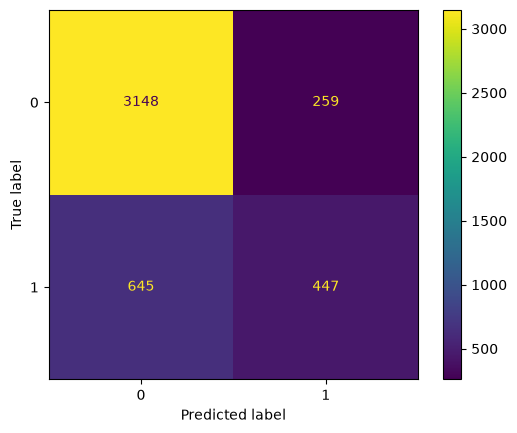

In [12]:
disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
disp.plot()
plt.show()

In [13]:
accuracy_score(y_pred, y_test)

0.7990664592131584

In [14]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test) #applies argmax to predicted probabilities matrix
accuracy_score(y_pred, y_test)

0.7990664592131584

In [15]:
y.value_counts()

left
0    11428
1     3567
Name: count, dtype: int64

In [16]:
y.value_counts(normalize=True)*100

left
0    76.212071
1    23.787929
Name: proportion, dtype: float64

## Stratification of sampling

In [17]:
hr = pd.read_csv("HR_comma_sep.csv")
hr.dtypes
dum_hr = pd.get_dummies(hr, drop_first=True)
# dum_hr.dtypes
X = dum_hr.drop('left', axis=1)
y = dum_hr['left']
y.value_counts()

left
0    11428
1     3567
Name: count, dtype: int64

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=25, stratify=y)

In [19]:
y_train.value_counts(normalize=True)*100

left
0    76.209985
1    23.790015
Name: proportion, dtype: float64

In [20]:
y_test.value_counts(normalize=True)*100

left
0    76.216937
1    23.783063
Name: proportion, dtype: float64

In [21]:
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test) #applies argmax to predicted probabilities matrix
accuracy_score(y_pred, y_test)

0.8061791509224272

In [22]:
lr = LogisticRegression(penalty = 'l1', solver='liblinear')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test) #applies argmax to predicted probabilities matrix
accuracy_score(y_pred, y_test)

0.8015114469882196

In [23]:
solvers = 'saga'
penalty = ['l1', 'l2', 'elasticnet', None]
scores = []
for p in penalty:
    lr = LogisticRegression(solver=solvers, penalty=p, l1_ratio=0.5)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    scores.append([p, accuracy_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=['penalty', 'score'])
df_scores.sort_values('score', ascending=False)


,penalty,score
0,l1,0.757724
1,l2,0.757724
2,elasticnet,0.757724
3,NaN,0.757724


In [24]:
solvers = ['sag', 'newton-cg', 'newton-cholesky', 'lbfgs']
penalty = ['l2', None]
scores = []
for p in penalty:
    for s in solvers:
        lr = LogisticRegression(solver=s, penalty=p)
        lr.fit(X_train, y_train)
        y_pred = lr.predict(X_test)
        scores.append([p,s, accuracy_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=['penalty','solver', 'score'])
df_scores.sort_values('score', ascending=False)

,penalty,solver,score
7,NaN,lbfgs,0.808180
3,l2,lbfgs,0.806179
1,l2,newton-cg,0.799733
2,l2,newton-cholesky,0.799066
6,NaN,newton-cholesky,0.799066
5,NaN,newton-cg,0.799066
0,l2,sag,0.750611
4,NaN,sag,0.750611


## BreastCancer

In [25]:
b_can = pd.read_csv("BreastCancer.csv")

X = b_can.drop(['Class', 'Code'], axis=1)
y = b_can['Class']
y.value_counts()

Class
Benign       458
Malignant    241
Name: count, dtype: int64

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=25, stratify=y)

In [27]:
# Compare different solvers with L2 and No Penalty

solvers = ['sag', 'newton-cg', 'newton-cholesky', 'lbfgs']
penalties = ['l2', None]

scores = []

for p in penalties:
    for s in solvers:

        lr = LogisticRegression(
            solver=s,
            penalty=p,
            max_iter=5000,
            random_state=25
        )

        lr.fit(X_train, y_train)

        y_pred = lr.predict(X_test)

        scores.append([p, s, accuracy_score(y_test, y_pred)])

df_scores = pd.DataFrame(
    scores,
    columns=['Penalty', 'Solver', 'Accuracy']
)

df_scores = df_scores.sort_values(
    by='Accuracy',
    ascending=False
)

print(df_scores)

  Penalty           Solver  Accuracy
0      l2              sag  0.966667
1      l2        newton-cg  0.966667
2      l2  newton-cholesky  0.966667
3      l2            lbfgs  0.966667
4     NaN              sag  0.966667
5     NaN        newton-cg  0.966667
6     NaN  newton-cholesky  0.966667
7     NaN            lbfgs  0.966667


In [28]:

# Compare different penalties using the SAGA solver
solver = 'saga'
penalties = ['l1', 'l2', 'elasticnet', None]

scores = []

for p in penalties:

    if p == 'elasticnet':
        lr = LogisticRegression(
            solver=solver,
            penalty=p,
            l1_ratio=0.5,
            max_iter=5000,
            random_state=25
        )
    else:
        lr = LogisticRegression(
            solver=solver,
            penalty=p,
            max_iter=5000,
            random_state=25
        )

    lr.fit(X_train, y_train)

    y_pred = lr.predict(X_test)

    scores.append([p, accuracy_score(y_test, y_pred)])

df_scores = pd.DataFrame(
    scores,
    columns=['Penalty', 'Accuracy']
)

df_scores = df_scores.sort_values(
    by='Accuracy',
    ascending=False
)

print(df_scores)

      Penalty  Accuracy
0          l1  0.966667
1          l2  0.966667
2  elasticnet  0.966667
3         NaN  0.966667
